<a href="https://colab.research.google.com/github/akashkumarcs24-cloud/BIS_LAB/blob/main/ParticleSwarmOptimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rastrigin test -> best value: 0.994959
iter    0  best = 3.919599
iter   20  best = 2.537690
iter   40  best = 2.310692
iter   60  best = 2.215481
iter   80  best = 2.170463
iter  100  best = 2.106601
iter  120  best = 2.069625
iter  140  best = 2.059148
iter  160  best = 2.030255
iter  180  best = 2.019990
iter  200  best = 2.016655
iter  220  best = 2.013885
iter  240  best = 2.013544
iter  260  best = 2.013217
iter  280  best = 2.013189

Optimal duration T = 1.509 s, fitness = 2.0132
Max |velocity|     = 0.939 rad/s (limit 1.5)
Max |acceleration| = 2.426 rad/s^2 (limit 3.0)
Final joint angles reached: [ 0.8 -0.5  0.6  0.3 -0.4  0.9]


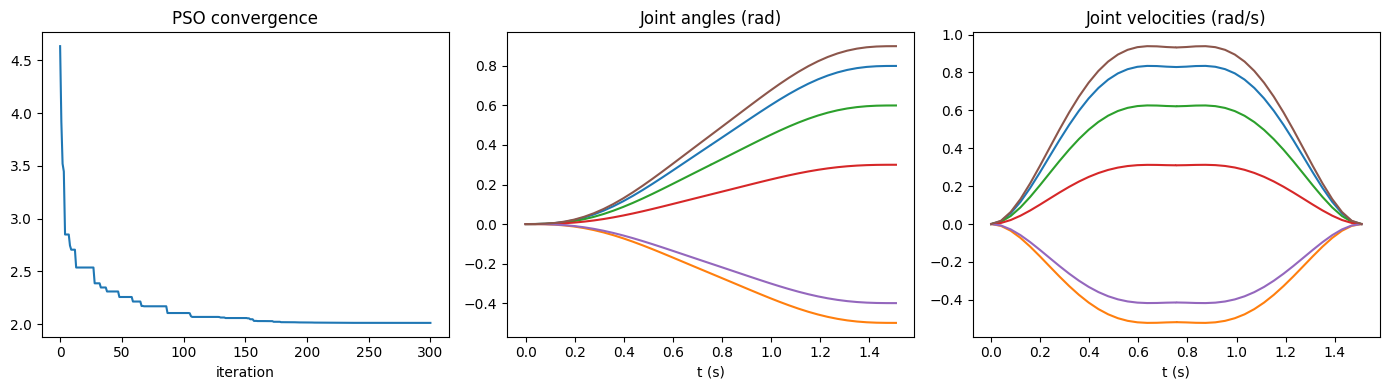

In [ ]:
"""
Particle Swarm Optimization (PSO) with a trajectory-planning demo.

Follows the paper's formulation:
    v[t+1] = w*v[t] + c1*r1*(pbest - x[t]) + c2*r2*(gbest - x[t])   (Eq. 14)
    x[t+1] = x[t] + v[t+1]                                          (Eq. 15)
    f(x)   = w1*Time(x) + w2*Energy(x)                              (Eq. 16)

Only numpy is required.
"""
import numpy as np

# np.trapz was renamed to np.trapezoid in NumPy 2.0
_trapz = getattr(np, "trapezoid", None) or np.trapz


# --------------------------------------------------------------------------
# Generic PSO
# --------------------------------------------------------------------------
class PSO:
    def __init__(self, fitness, lower, upper, n_particles=40, max_iter=200,
                 w_start=0.9, w_end=0.4, c1=2.0, c2=2.0, vmax_frac=0.2,
                 tol=1e-9, patience=40, seed=None):
        """
        fitness : callable(x: ndarray[dim]) -> float  (minimized)
        lower, upper : arrays of length dim (search bounds)
        w_start, w_end : inertia weight decays linearly (helps avoid the
                         premature convergence the paper mentions)
        vmax_frac : velocity clamp as a fraction of the search range
        patience : stop if gbest improves < tol for this many iterations
        """
        self.f = fitness
        self.lo = np.asarray(lower, float)
        self.hi = np.asarray(upper, float)
        self.dim = self.lo.size
        self.n = n_particles
        self.max_iter = max_iter
        self.w_start, self.w_end = w_start, w_end
        self.c1, self.c2 = c1, c2
        self.vmax = vmax_frac * (self.hi - self.lo)
        self.tol, self.patience = tol, patience
        self.rng = np.random.default_rng(seed)

    def run(self, verbose=False):
        rng = self.rng
        # 1. Initialize population
        x = rng.uniform(self.lo, self.hi, (self.n, self.dim))
        v = rng.uniform(-self.vmax, self.vmax, (self.n, self.dim))
        # 2. Individual fitness
        fit = np.array([self.f(p) for p in x])
        pbest, pbest_fit = x.copy(), fit.copy()
        g = np.argmin(pbest_fit)
        gbest, gbest_fit = pbest[g].copy(), pbest_fit[g]

        history, stall = [gbest_fit], 0
        for t in range(self.max_iter):
            w = self.w_start - (self.w_start - self.w_end) * t / self.max_iter
            r1 = rng.random((self.n, self.dim))
            r2 = rng.random((self.n, self.dim))
            # 3. Update velocity and position (Eq. 14, 15)
            v = w * v + self.c1 * r1 * (pbest - x) + self.c2 * r2 * (gbest - x)
            v = np.clip(v, -self.vmax, self.vmax)
            x = np.clip(x + v, self.lo, self.hi)
            # 4. Evaluate; keep better personal/global bests
            fit = np.array([self.f(p) for p in x])
            better = fit < pbest_fit
            pbest[better], pbest_fit[better] = x[better], fit[better]
            g = np.argmin(pbest_fit)
            improved = gbest_fit - pbest_fit[g]
            if pbest_fit[g] < gbest_fit:
                gbest, gbest_fit = pbest[g].copy(), pbest_fit[g]
            history.append(gbest_fit)
            stall = stall + 1 if improved < self.tol else 0
            if verbose and t % 20 == 0:
                print(f"iter {t:4d}  best = {gbest_fit:.6f}")
            # 5. Termination check
            if stall >= self.patience:
                break
        return gbest, gbest_fit, np.array(history)


# --------------------------------------------------------------------------
# Quintic polynomial trajectory helpers (Eq. 13)
# --------------------------------------------------------------------------
def quintic_coeffs(q0, v0, a0, qf, vf, af, T):
    """Coefficients a0..a5 for each joint (arrays of shape [n_joints])."""
    q0, v0, a0, qf, vf, af = map(np.asarray, (q0, v0, a0, qf, vf, af))
    A = np.array([[T**3, T**4, T**5],
                  [3*T**2, 4*T**3, 5*T**4],
                  [6*T, 12*T**2, 20*T**3]])
    rhs = np.stack([qf - q0 - v0*T - 0.5*a0*T**2,
                    vf - v0 - a0*T,
                    af - a0])                       # shape [3, n_joints]
    a3, a4, a5 = np.linalg.solve(A, rhs)
    return np.stack([q0, v0, 0.5*a0, a3, a4, a5])   # shape [6, n_joints]


def eval_quintic(c, t):
    """Return q, qd, qdd at times t (array) -> each [len(t), n_joints]."""
    t = t[:, None]
    q = sum(c[k] * t**k for k in range(6))
    qd = sum(k * c[k] * t**(k-1) for k in range(1, 6))
    qdd = sum(k*(k-1) * c[k] * t**(k-2) for k in range(2, 6))
    return q, qd, qdd


def build_trajectory(x, q_start, q_end, n_joints, n_samples=20):
    """
    Decision vector x = [T, q_via(n), v_via(n)].
    Two quintic segments (each T/2) joined at a free via-point, with zero
    velocity/acceleration at start and end, and zero acceleration at the via.
    n_samples points per segment (the paper uses 20).
    """
    T = x[0]
    q_via = x[1:1 + n_joints]
    v_via = x[1 + n_joints:1 + 2 * n_joints]
    z = np.zeros(n_joints)
    c1 = quintic_coeffs(q_start, z, z, q_via, v_via, z, T / 2)
    c2 = quintic_coeffs(q_via, v_via, z, q_end, z, z, T / 2)
    t = np.linspace(0, T / 2, n_samples)
    q1, qd1, qdd1 = eval_quintic(c1, t)
    q2, qd2, qdd2 = eval_quintic(c2, t)
    t_all = np.concatenate([t, t + T / 2])
    return (t_all, np.vstack([q1, q2]), np.vstack([qd1, qd2]),
            np.vstack([qdd1, qdd2]))


# --------------------------------------------------------------------------
# Fitness: f = w1*Time + w2*Energy (+ penalty for violated limits)
# --------------------------------------------------------------------------
def make_fitness(q_start, q_end, v_max, a_max, w1=1.0, w2=0.05, penalty=1e3):
    n = len(q_start)

    def fitness(x):
        t, q, qd, qdd = build_trajectory(x, q_start, q_end, n)
        time_cost = x[0]
        # Energy proxy: integral of sum of squared joint accelerations
        energy = _trapz((qdd ** 2).sum(axis=1), t)
        # Penalize velocity / acceleration limit violations
        viol = (np.clip(np.abs(qd) - v_max, 0, None).sum()
                + np.clip(np.abs(qdd) - a_max, 0, None).sum())
        return w1 * time_cost + w2 * energy + penalty * viol

    return fitness


# --------------------------------------------------------------------------
# Demo
# --------------------------------------------------------------------------
if __name__ == "__main__":
    # 1) Sanity check on a standard benchmark (Rastrigin, optimum = 0)
    def rastrigin(x):
        return 10 * x.size + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))

    best, val, _ = PSO(rastrigin, [-5.12]*5, [5.12]*5, n_particles=50,
                       max_iter=300, seed=0).run()
    print("Rastrigin test -> best value:", round(val, 6))

    # 2) Trajectory optimization for a 6-axis arm (joint space, radians)
    n = 6
    q_start = np.zeros(n)
    q_end = np.array([0.8, -0.5, 0.6, 0.3, -0.4, 0.9])
    v_max, a_max = 1.5, 3.0          # rad/s, rad/s^2 per joint

    lo = np.concatenate([[0.5], np.full(n, -1.5), np.full(n, -v_max)])
    hi = np.concatenate([[8.0], np.full(n, 1.5), np.full(n, v_max)])

    fit = make_fitness(q_start, q_end, v_max, a_max, w1=1.0, w2=0.05)
    pso = PSO(fit, lo, hi, n_particles=60, max_iter=300, seed=1)
    x_best, f_best, hist = pso.run(verbose=True)

    t, q, qd, qdd = build_trajectory(x_best, q_start, q_end, n)
    print(f"\nOptimal duration T = {x_best[0]:.3f} s, fitness = {f_best:.4f}")
    print(f"Max |velocity|     = {np.abs(qd).max():.3f} rad/s (limit {v_max})")
    print(f"Max |acceleration| = {np.abs(qdd).max():.3f} rad/s^2 (limit {a_max})")
    print("Final joint angles reached:", np.round(q[-1], 3))

    try:
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(1, 3, figsize=(14, 4))
        ax[0].plot(hist); ax[0].set_title("PSO convergence"); ax[0].set_xlabel("iteration")
        ax[1].plot(t, q); ax[1].set_title("Joint angles (rad)"); ax[1].set_xlabel("t (s)")
        ax[2].plot(t, qd); ax[2].set_title("Joint velocities (rad/s)"); ax[2].set_xlabel("t (s)")
        plt.tight_layout(); plt.show()
    except ImportError:
        pass